### 💡 Decision Tree Regression
Decision Tree Regression은 데이터를 특정 조건에 따라 반복적으로 분할하고, 최종적으로 도달한 리프 노드의 대표값을 이용해 수치형 데이터를 예측하는 머신러닝 알고리즘이다.

대표적인 활용 사례로는 주택 가격 예측, 직원 연봉 예측, 상품 판매량 예측 등이 있다.

DecisionTreeClassification에서는 동일한 클래스끼리 분리를 하면 트리 구조를 만들었지만, Regression에서는 평균값을 활용해 비슷한 수치끼리 분류한다는 특징이 있다.

#### 1️⃣ 회귀 트리의 분할 기준 (MSE)
MSE(Mean Squared Error)는 실제값과 예측값의 차이를 제곱한 후 평균을 구한 값이다.

공식으로는 다음과 같다.

$MSE=\frac{1}{n}\sum_{i=1}^{n}(y_i-\bar{y})^2$

예를들어 현재 노드에 다음과 같은 시험 점수 데이터가 있다고 가정해보자.

In [4]:
import numpy as np

scores = np.array([20, 30, 40])

mean = np.mean(scores)
mse = np.mean((scores - mean)**2)

print("Mean:", mean)
print("MSE:", mse)

Mean: 30.0
MSE: 66.66666666666667


노드 내부의 값들이 평균으로부터 멀리 떨어져있을수록 오차가 커지고, 자연스럽게 MSE도 커지게 된다.
- MSE가 낮다 &rightarrow; 노드 내부의 Target 값들이 서로 비슷하다.
- MSE가 높다 &rightarrow; 노드 내부의 Target 값들이 서로 다르다.
- MSE가 0이다 &rightarrow; 노드 내부의 Target 값들이 서로 동일하다.

> 회귀 트리는 분할 이후의 가중 평균 MSE가 가장 작아지는 조건을 선택한다.

분류트리에서 사용했던 `Gini`를 `MSE`로 대체하는 것이다.

In [6]:
# DecisionTreeRegressor 사용하기
# 데이터 준비
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

diabetes = load_diabetes()

X = diabetes.data
y = diabetes.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# 모델 생성
model = DecisionTreeRegressor(
    criterion="squared_error",
    random_state=42
)

# 모델 학습
model.fit(X_train, y_train)

# 값 예측
y_pred = model.predict(X_test)

print(y_pred[:5])

[206.  99. 170. 268. 183.]


In [ ]:
# 모델 성능 평가
from sklearn.metrics import mean_squared_error, r2_score

train_pred = model.predict(X_train)

# MSE (평균 제곱 오차) : 0에 가까울수록 좋은 방향이다
# R2 (평균값 예측 대비 모델의 설명력) : 1에 가까울수록 좋은 방향이다
print("Train MSE :", mean_squared_error(y_train, train_pred))
print("Test MSE :", mean_squared_error(y_test, y_pred))

print("Train R2 :", r2_score(y_train, train_pred))
print("Test R2 :", r2_score(y_test, y_pred))

Train MSE : 0.0
Test MSE : 4976.797752808989
Train R2 : 1.0
Test R2 : 0.060653981041140725


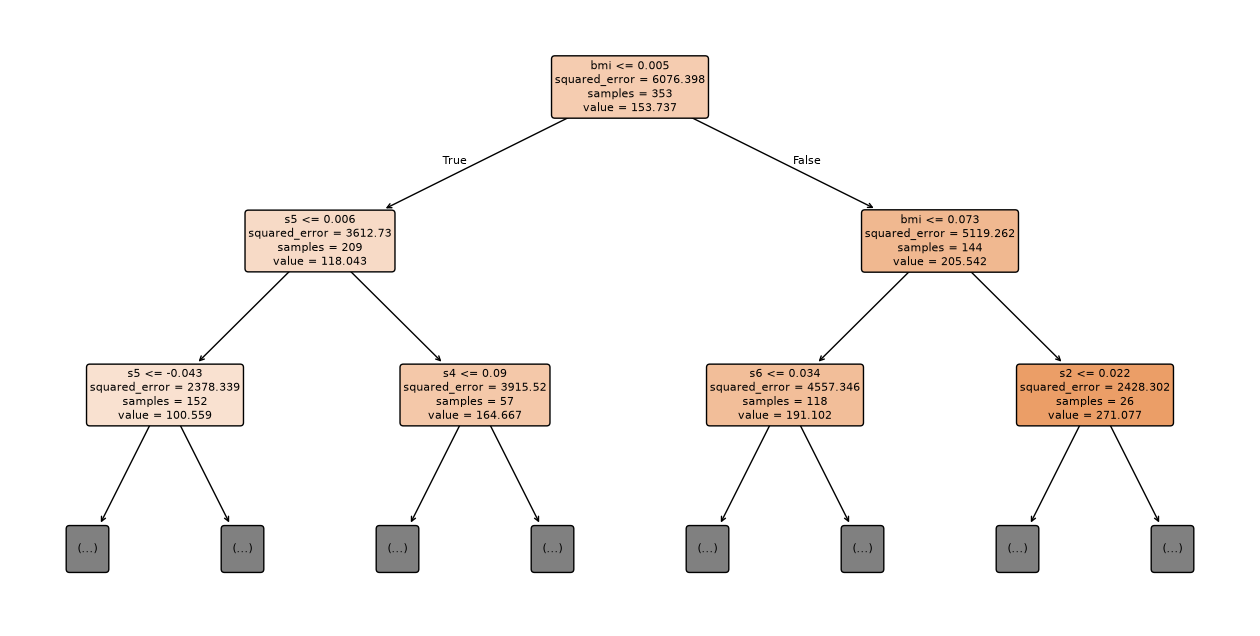

In [8]:
# 모델 시각화
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=diabetes.feature_names,
    filled=True,
    rounded=True,
    max_depth=2
)

plt.show()

#### ✅ 노드 구조 해석
- `bmi <= 0.005` : 분할 조건
- `squared_error` : 현재 노드의 MSE
- `samples = 100` : 노드의 데이터 개수
- `value = 150.0` : Target 평균값

---
#### 실습문제

학습 데이터 예측 값 : [4.  3.  5.  2.5 8.5 7.  5.8 2.  4.3 9.2 2.8 5.5 3.7 4.8 6.  3.3]
실제 데이터 값 : [4.  3.  5.  2.5 8.5 7.  5.8 2.  4.3 9.2 2.8 5.5 3.7 4.8 6.  3.3]
테스트 데이터 예측 값 : [2.  8.5 6.  2. ]
실제 테스트 데이터 값 : [1.5 7.8 6.5 1.8]
학습 데이터의 MSE : 0.0
테스트 데이터의 MSE : 0.25750000000000006
학습 데이터의 R2 : 1.0
테스트 데이터의 R2 : 0.9669235709698137


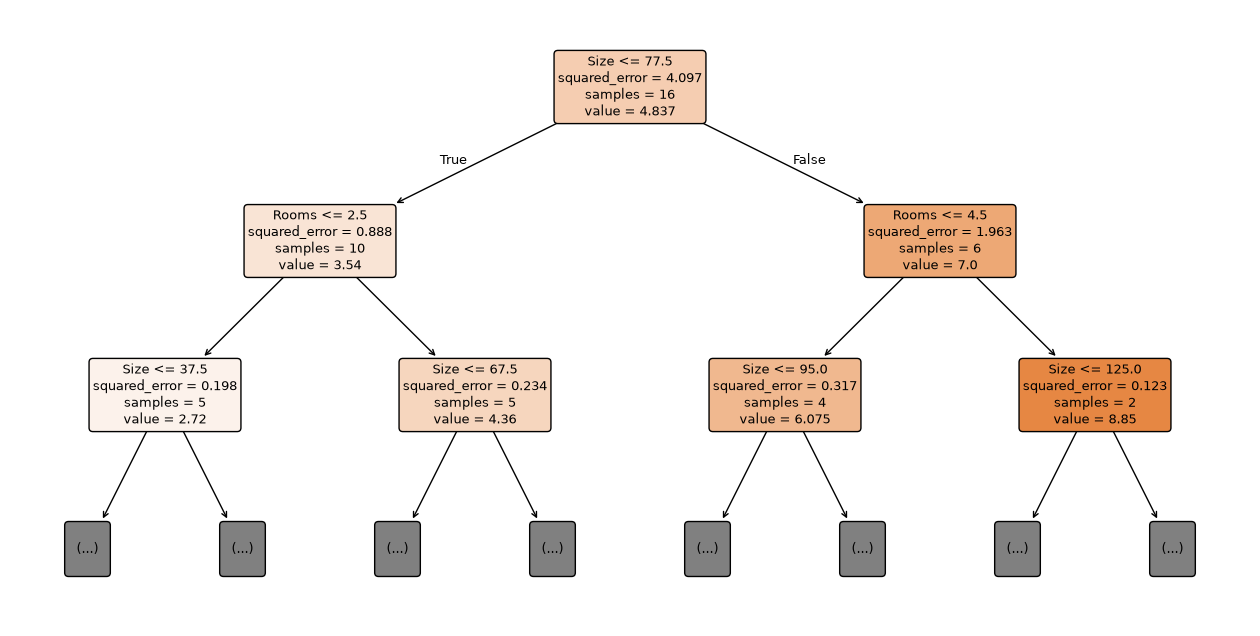

[5.8]


In [18]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, r2_score

# 주택 크기(m²), 방 개수
X = np.array([
    [20, 1], [25, 1], [30, 1], [35, 2],
    [40, 2], [45, 2], [50, 2], [55, 3],
    [60, 3], [65, 3], [70, 3], [75, 3],
    [80, 4], [85, 4], [90, 4], [95, 4],
    [100, 4], [110, 5], [120, 5], [130, 5]
])

# 주택 가격 (억 원)
y = np.array([
    1.5, 1.8, 2.0, 2.5, 2.8,
    3.0, 3.3, 3.7, 4.0, 4.3,
    4.8, 5.0, 5.5, 5.8, 6.0,
    6.5, 7.0, 7.8, 8.5, 9.2
])

feature_names = ["Size", "Rooms"]

# 1. 학습 데이터 80%, 테스트 데이터 20%로 분리하기
# random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

# 2. DecisionTreeRegressor 모델 생성 및 학습하기
model = DecisionTreeRegressor(
    criterion="squared_error",
    random_state=42
)

model.fit(X_train, y_train)

# 3. 학습 데이터와 테스트 데이터의 예측값 구하기
y_train_pred =model.predict(X_train)
y_test_pred = model.predict(X_test)
print("학습 데이터 예측 값 :", y_train_pred)
print("실제 데이터 값 :", y_train)
print("테스트 데이터 예측 값 :", y_test_pred)
print("실제 테스트 데이터 값 :", y_test)

# 4. 학습 데이터와 테스트 데이터의 MSE, R2 출력하기
# MSE
print("학습 데이터의 MSE :", mean_squared_error(y_train, y_train_pred))
print("테스트 데이터의 MSE :", mean_squared_error(y_test, y_test_pred))

# R2
print("학습 데이터의 R2 :", r2_score(y_train, y_train_pred))
print("테스트 데이터의 R2 :", r2_score(y_test, y_test_pred))

# 5. plot_tree()를 이용하여 모델 시각화하기
plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names = ["Size", "Rooms"],
    filled=True,
    rounded=True,
    max_depth=2
)

plt.show()

# 6. 크기가 85m²이고 방이 3개인 주택의 가격 예측하기
X_new = np.array([[85, 3]])
y_pred_new = model.predict(X_new)
print(y_pred_new)